# ♻️ Clasificación de Residuos Sólidos con CNN
## Pipeline completo: del problema al despliegue (versión con 4 fuentes de datos)

**Curso:** IS056B — Ingeniería del Conocimiento | UNCP 2026-II

**Integrantes:**
- Echegoyen Rojas Anahi
- Espinoza Inga Deysi
- Paucar Ramirez Carolina
- Tomas Rivera Andriy

**Datasets:** Roboflow *Garbage-Classification* (v6) · Roboflow *Waste-Classification* (v3) · **RealWaste** (UCI) · **TACO** (recortes)

**Modelos comparados (3):**
1. **CNN propia** (desde cero, con bloques residuales)
2. **Transfer Learning — Feature Extraction** (MobileNetV2 con el **backbone congelado**)
3. **Transfer Learning — Fine-Tuning** (MobileNetV2 con **congelamiento parcial de capas**, protocolo de 2 fases)

> Ejecutar en **Google Colab con GPU T4** (Entorno de ejecución → Cambiar tipo → T4 GPU).

## ⚙️ Fase 0: Configuración del entorno

In [ ]:
import os, json, glob, time, gc, re, random, shutil, subprocess, sys, datetime, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
from PIL import Image, ImageOps
from tqdm.auto import tqdm
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

# ---- Interruptores de datos (pon False para desactivar una fuente) ----
USAR_REALWASTE = True
USAR_TACO = True
MAX_TRAIN = 3000      # máximo de imágenes de train por clase (control de desbalance)

SEED = 42
tf.random.set_seed(SEED); np.random.seed(SEED); random.seed(SEED)
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
STAMP = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

# Google Drive: solo para guardar resultados y modelos (no se leen imágenes desde Drive)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/proyecto_residuos'
except Exception:
    OUT_DIR = '/content/proyecto_residuos'
os.makedirs(OUT_DIR, exist_ok=True)

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.stdout.strip(): print(r.stdout[-1500:])
    if r.returncode != 0:
        print(r.stderr[-2500:]); raise RuntimeError(f"Falló: {cmd}")

def sh_live(cmd):
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout: print(line.rstrip())
    p.wait(); return p.returncode

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive


## 📝 Fase 1: Definición del problema

| Pregunta | Respuesta |
|---|---|
| ¿Qué problema resuelve? | Clasificar automáticamente una imagen de residuo sólido e indicar a qué tacho debe ir (base de un tacho inteligente). |
| ¿Binaria o multiclase? | Multiclase: 7 clases (`metal, organico, otros, papel_carton, peligroso, plastico, vidrio`). |
| Métrica principal | **F1 macro** (hay desbalance de clases) y accuracy como referencia. |
| Restricciones | Entrenar en Colab (T4), modelo liviano para app, funcionar con imágenes de cámara real. |
| Baseline trivial | Clasificador aleatorio = 1/7 ≈ 14 %; y predecir siempre la clase mayoritaria. |
| Reto principal | Pasar de fotos "de estudio" a **residuos en condiciones reales** (fondos desordenados, luz variable, objetos sucios o parcialmente ocultos). Por eso se suman RealWaste y TACO. |

## 📥 Fase 2: Datasets y EDA

| Clave | Dataset | Qué aporta |
|---|---|---|
| `ds1` | Roboflow Garbage-Classification v6 | Objetos aislados, 13 clases (vidrio por color, baterías, ropa, zapatos…) |
| `ds2` | Roboflow Waste-Classification v3 | Mucho residuo orgánico, bolsas y botellas |
| `rw` | **RealWaste** (UCI, CC BY 4.0): 4 752 fotos, 9 clases, tomadas en un vertedero | Residuos reales, sucios y mezclados |
| `taco` | **TACO**: fotos de basura en calles, bosques y playas, con cajas anotadas | Fondos reales y luz variable (se **recortan** los objetos anotados) |




In [ ]:
from getpass import getpass
DS1, DS2 = "/content/ds1_garbage", "/content/ds2_waste"
if not (os.path.isdir(DS1) and os.path.isdir(DS2)):
    sh("pip install -q roboflow")
    from roboflow import Roboflow
    rf = Roboflow(api_key=getpass("API key de Roboflow: "))
    rf.workspace("garbage-detection-najwv").project("garbage-classification-7jjkg").version(6).download("folder", location=DS1)
    rf.workspace("waste-classification-bweuv").project("waste-classification-4j3md").version(3).download("folder", location=DS2)
for p in (DS1, DS2):
    print(p, "->", os.listdir(p) if os.path.exists(p) else "⚠️ NO ENCONTRADO")

API key de Roboflow: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/ds1_garbage in folder:: 100%|██████████| 21608/21608 [00:02<00:00, 8253.99it/s]

loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to /content/ds2_waste in folder:: 100%|██████████| 25584/25584 [00:03<00:00, 7081.93it/s]


/content/ds1_garbage -> ['train', 'README.dataset.txt', 'valid', 'README.roboflow.txt', 'test']
/content/ds2_waste -> ['train', 'valid', 'README.roboflow.txt', 'test']


**RealWaste:** descarga directa desde UCI (≈ 650 MB, tarda unos minutos).
Cita: Single, Iranmanesh & Raad (2023), *RealWaste*, UCI ML Repository, doi:10.24432/C5SS4G (licencia CC BY 4.0).

In [ ]:
RW_DIR, RW_ROOT = "/content/realwaste", None
if USAR_REALWASTE:
    if not os.path.isdir(RW_DIR):
        sh("wget -q -O /content/realwaste.zip https://archive.ics.uci.edu/static/public/908/realwaste.zip")
        sh(f"unzip -q /content/realwaste.zip -d {RW_DIR}")
    for root, dirs, _ in os.walk(RW_DIR):
        if "Cardboard" in dirs and "Plastic" in dirs:
            RW_ROOT = root; break
    print("RealWaste en:", RW_ROOT)
else:
    print("RealWaste desactivado.")

RealWaste en: /content/realwaste/realwaste-main/RealWaste


**TACO:** las anotaciones están en formato COCO y las imágenes en Flickr. El script oficial `download.py` las descarga
(tarda varios minutos y **algunas URLs pueden estar caídas**; es normal que falten algunas fotos).

*Alternativa si el script falla o es muy lento:* descarga TACO desde Kaggle (busca "TACO trash dataset"; trae carpetas `batch_1`…`batch_15` y `annotations.json`),
descomprímela en `/content/taco_kaggle/` y vuelve a ejecutar esta celda.

In [ ]:
TACO_REPO = "/content/TACO"
def find_taco():
    for base in ["/content/TACO/data", "/content/taco_kaggle"]:
        for root, dirs, files in os.walk(base):
            if "annotations.json" in files and any(d.startswith("batch_") for d in dirs):
                return root
    return None

TACO_DATA = TACO_ANN = None
if USAR_TACO:
    TACO_DATA = find_taco()
    if TACO_DATA is None:
        if not os.path.isdir(TACO_REPO):
            sh("git clone -q https://github.com/pedropro/TACO.git /content/TACO")
        print("Descargando imágenes de TACO (puede tardar 5-20 min)...")
        sh_live("cd /content/TACO && python download.py")
        TACO_DATA = find_taco()
    TACO_ANN = os.path.join(TACO_DATA, "annotations.json") if TACO_DATA else None
    n_img = len(glob.glob(os.path.join(TACO_DATA, "batch_*", "*"))) if TACO_DATA else 0
    print("TACO en:", TACO_DATA, "| imágenes descargadas:", n_img)
    assert n_img > 100, "Pocas imágenes de TACO: revisa la descarga o usa la alternativa de Kaggle"
else:
    print("TACO desactivado.")

Descargando imágenes de TACO (puede tardar 5-20 min)...
Note. If for any reason the connection is broken. Just call me again and I will start where I left.
Loading: [..............................] - 0/1500
Loading: [..............................] - 1/1500
Loading: [..............................] - 2/1500
Loading: [..............................] - 3/1500
Loading: [..............................] - 4/1500
Loading: [..............................] - 5/1500
Loading: [..............................] - 6/1500
Loading: [..............................] - 7/1500
Loading: [..............................] - 8/1500
Loading: [..............................] - 9/1500
Loading: [..............................] - 10/1500
Loading: [..............................] - 11/1500
Loading: [..............................] - 12/1500
Loading: [..............................] - 13/1500
Loading: [..............................] - 14/1500
Loading: [..............................] - 15/1500
Loading: [............

### 2.1 Clases originales de cada dataset

In [ ]:
def count_split(root):
    out = {}
    for split in ['train', 'valid', 'test']:
        sp = os.path.join(root, split)
        if not os.path.isdir(sp): continue
        for c in sorted(os.listdir(sp)):
            cp = os.path.join(sp, c)
            if os.path.isdir(cp):
                out.setdefault(c, {})[split] = len([f for f in os.listdir(cp) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
    return pd.DataFrame(out).T.fillna(0).astype(int)

print("=== Dataset 1: Garbage-Classification ==="); display(count_split(DS1))
print("=== Dataset 2: Waste-Classification ===");   display(count_split(DS2))
if USAR_REALWASTE:
    print("=== RealWaste (sin splits; se dividen en 2.3) ===")
    display(pd.Series({c: len(os.listdir(os.path.join(RW_ROOT, c))) for c in sorted(os.listdir(RW_ROOT))}, name='imágenes'))
if USAR_TACO:
    ann_ = json.load(open(TACO_ANN))
    print(f"=== TACO: {len(ann_['images'])} fotos, {len(ann_['annotations'])} objetos anotados, {len(ann_['categories'])} categorías ===")

=== Dataset 1: Garbage-Classification ===


,train,valid,test
battery,1391,80,89
biological,1426,77,94
brown-glass,881,47,55
cardboard,1303,74,78
cardboard plastic,1,0,0
clothes,5446,400,463
green-glass,846,78,50
metal,1055,95,69
paper,481,32,90
plastic,1190,96,73


=== Dataset 2: Waste-Classification ===


,train,valid,test
ewaste,334,43,25
food_waste,14376,2038,1032
leaf_waste,2155,310,152
metal_cans,1060,136,72
paper_waste,1372,211,105
plastic_bags,282,39,17
plastic_bottles,579,86,41
wood_waste,885,146,60


=== RealWaste (sin splits; se dividen en 2.3) ===


,imágenes
Cardboard,461
Food Organics,411
Glass,420
Metal,790
Miscellaneous Trash,495
Paper,500
Plastic,921
Textile Trash,318
Vegetation,436


=== TACO: 1500 fotos, 4784 objetos anotados, 60 categorías ===


### 2.2 Unificación de clases
Las clases originales de cada dataset se asignan a **7 clases finales**. Las que no tienen equivalencia clara se descartan (`None`) en vez de forzarlas.

In [ ]:
MAP1 = {  # Roboflow Garbage-Classification
    'battery': 'peligroso', 'biological': 'organico',
    'brown-glass': 'vidrio', 'green-glass': 'vidrio', 'white-glass': 'vidrio',
    'cardboard': 'papel_carton', 'paper': 'papel_carton',
    'metal': 'metal', 'plastic': 'plastico',
    'clothes': 'otros', 'shoes': 'otros', 'trash': 'otros',
    'cardboard plastic': None,   # mezcla ambigua, se descarta
}
MAP2 = {  # Roboflow Waste-Classification
    'ewaste': 'peligroso', 'food_waste': 'organico', 'leaf_waste': 'organico',
    'metal_cans': 'metal', 'paper_waste': 'papel_carton',
    'plastic_bags': 'plastico', 'plastic_bottles': 'plastico',
    'wood_waste': None,          # se descarta
}
MAP_RW = {  # RealWaste
    'Cardboard': 'papel_carton', 'Paper': 'papel_carton',
    'Food Organics': 'organico', 'Vegetation': 'organico',
    'Glass': 'vidrio', 'Metal': 'metal', 'Plastic': 'plastico',
    'Miscellaneous Trash': 'otros', 'Textile Trash': 'otros',
}

def map_taco(nombre):
    """TACO tiene ~60 categorías: se asignan por palabras clave. None = se descarta."""
    n = nombre.lower()
    if 'blister' in n: return None                       # envases mixtos aluminio/plástico
    if 'battery' in n: return 'peligroso'
    if 'glass' in n: return 'vidrio'
    if 'food waste' in n: return 'organico'
    if 'plastified' in n or 'paper cup' in n or 'tissue' in n: return 'otros'
    if 'foam' in n or 'styrofoam' in n: return 'otros'
    if any(k in n for k in ['shoe', 'cigarette', 'unlabeled', 'rope']): return 'otros'
    if 'squeezable' in n: return 'plastico'
    if 'metal' in n or re.search(r'\bcan\b', n) or any(k in n for k in ['foil', 'pop tab', 'aerosol']): return 'metal'
    if any(k in n for k in ['carton', 'paper', 'box', 'tube', 'magazine', 'wrapping']): return 'papel_carton'
    if any(k in n for k in ['plastic', 'bag', 'film', 'wrapper', 'container', 'cup', 'bottle', 'tub',
                            'tupperware', 'straw', 'utensil', 'crisp', 'six pack', 'lid', 'packet']): return 'plastico'
    return None

# Tacho sugerido por clase final (usado en la app)
BIN_MAP = {
    'plastico':     'Tacho blanco (plásticos)',
    'papel_carton': 'Tacho azul (papel y cartón)',
    'vidrio':       'Tacho verde (vidrio)',
    'metal':        'Tacho amarillo (metales)',
    'organico':     'Tacho marrón (orgánicos)',
    'peligroso':    'Tacho rojo (residuos peligrosos)',
    'otros':        'Tacho negro (no aprovechables)',
}
assert set(MAP1.values()) | set(MAP2.values()) | set(MAP_RW.values()) <= set(BIN_MAP) | {None}

if USAR_TACO:   # revisa cómo quedó la asignación de TACO; corrige map_taco si algo no te convence
    cats_ = json.load(open(TACO_ANN))['categories']
    display(pd.DataFrame({'categoria_TACO': [c['name'] for c in cats_],
                          'clase_final': [map_taco(c['name']) for c in cats_]}).sort_values('clase_final', na_position='last').reset_index(drop=True))

,categoria_TACO,clase_final
0,Aluminium foil,metal
1,Metal lid,metal
2,Drink can,metal
3,Aerosol,metal
4,Metal bottle cap,metal
5,Food Can,metal
6,Scrap metal,metal
7,Pop tab,metal
8,Food waste,organico
9,Rope & strings,otros


### 2.3 Construcción del dataset unificado (sin fugas de datos)
- Se **respetan los splits de Roboflow** (su aumento de datos está solo en *train*). RealWaste se divide 70/15/15 por clase. TACO se divide 70/15/15 **por foto original** (dos recortes de la misma foto nunca quedan en splits distintos).
- Se detectan **duplicados con hash perceptual (dHash)**: atrapa copias redimensionadas o recomprimidas, no solo idénticas.
- Se quitan del *train* las imágenes que aparezcan en val/test, de cualquier fuente.
- Se limita el *train* a `MAX_TRAIN` por clase, conservando primero las imágenes de RealWaste/TACO.
- Se usan enlaces simbólicos para no duplicar espacio en disco.

In [ ]:
rng = np.random.RandomState(SEED)
EXT = ('.jpg', '.jpeg', '.png')
rec = []
def add(path, split, clase, origen): rec.append((path, split, clase, origen))

# --- Roboflow (splits originales) ---
for root, mp, tag in [(DS1, MAP1, 'ds1'), (DS2, MAP2, 'ds2')]:
    for src, dst in [('train', 'train'), ('valid', 'val'), ('test', 'test')]:
        sp = os.path.join(root, src)
        if not os.path.isdir(sp): continue
        for c in os.listdir(sp):
            if c not in mp: print("⚠️ clase sin mapear:", tag, c); continue
            if mp[c] is None: continue
            for fn in os.listdir(os.path.join(sp, c)):
                if fn.lower().endswith(EXT): add(os.path.join(sp, c, fn), dst, mp[c], tag)

# --- RealWaste: 70/15/15 por clase original ---
if USAR_REALWASTE:
    for c in sorted(os.listdir(RW_ROOT)):
        final, cd = MAP_RW.get(c), os.path.join(RW_ROOT, c)
        if final is None or not os.path.isdir(cd): continue
        files = sorted(f for f in os.listdir(cd) if f.lower().endswith(EXT))
        rng.shuffle(files); n = len(files)
        for i, fn in enumerate(files):
            add(os.path.join(cd, fn), 'train' if i < 0.70*n else ('val' if i < 0.85*n else 'test'), final, 'rw')

# --- TACO: recortar cada objeto anotado; split por foto original ---
TACO_CROPS = "/content/taco_crops"
if USAR_TACO:
    ann = json.load(open(TACO_ANN))
    imgs = {im['id']: im for im in ann['images']}
    cats = {c['id']: c['name'] for c in ann['categories']}
    ids = sorted(imgs); np.random.RandomState(SEED).shuffle(ids)
    img_split = {i: ('train' if k < 0.70*len(ids) else ('val' if k < 0.85*len(ids) else 'test')) for k, i in enumerate(ids)}
    by_img = {}
    for a in ann['annotations']: by_img.setdefault(a['image_id'], []).append(a)
    os.makedirs(TACO_CROPS, exist_ok=True)
    skip, n_taco = Counter(), 0
    for iid, anns in tqdm(by_img.items(), desc="Recortando TACO"):
        info = imgs[iid]
        p = os.path.join(TACO_DATA, info['file_name'])
        if not os.path.exists(p): skip['foto_no_descargada'] += 1; continue
        try: im = Image.open(p).convert('RGB')
        except Exception: skip['foto_corrupta'] += 1; continue
        esperado = (info['width'], info['height'])
        if im.size != esperado:               # algunas fotos traen rotación EXIF
            im2 = ImageOps.exif_transpose(im)
            if im2.size == esperado: im = im2
            else: skip['tamano_no_coincide'] += 1; continue
        for a in anns:
            clase = map_taco(cats[a['category_id']])
            if clase is None: skip['categoria_descartada'] += 1; continue
            x, y, w, h = a['bbox']
            if w < 40 or h < 40: skip['recorte_muy_pequeno'] += 1; continue
            m = 0.10   # 10 % de contexto alrededor del objeto
            box = (max(0, int(x-m*w)), max(0, int(y-m*h)), min(im.width, int(x+w*(1+m))), min(im.height, int(y+h*(1+m))))
            crop = im.crop(box); crop.thumbnail((512, 512))
            outp = f"{TACO_CROPS}/{iid}_{a['id']}.jpg"
            crop.save(outp, quality=92)
            add(outp, img_split[iid], clase, 'taco'); n_taco += 1
    print(f"Recortes TACO creados: {n_taco} | omitidos: {dict(skip)}")

df = pd.DataFrame(rec, columns=['path', 'split', 'clase', 'origen'])
print("Imágenes antes de limpiar:", len(df))
display(df.groupby(['origen', 'split']).size().unstack(fill_value=0))

Recortando TACO:   0%|          | 0/1500 [00:00<?, ?it/s]

Recortes TACO creados: 3869 | omitidos: {'recorte_muy_pequeno': 908, 'categoria_descartada': 7}
Imágenes antes de limpiar: 54691


split,test,train,val
origen,,,
ds1,1356,18908,1341
ds2,1444,20158,2863
rw,710,3329,713
taco,552,2761,556


In [ ]:
# Hash perceptual dHash (17x16 -> 256 bits). Las imágenes corruptas devuelven None.
from concurrent.futures import ThreadPoolExecutor
def dhash(path):
    try:
        with Image.open(path) as im:
            im.draft('L', (96, 96))
            g = np.asarray(im.convert('L').resize((17, 16), Image.LANCZOS), dtype=np.int16)
        return format(int(''.join('1' if b else '0' for b in (g[:, 1:] > g[:, :-1]).ravel()), 2), '064x')
    except Exception:
        return None

t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    df['hash'] = list(tqdm(ex.map(dhash, df['path'].tolist()), total=len(df), desc="Hash"))
print(f"Hash calculado en {(time.time()-t0)/60:.1f} min")

n0 = len(df); df = df[df['hash'].notna()]
print("Imágenes corruptas eliminadas:", n0 - len(df))

eval_hashes = set(df[df.split != 'train']['hash'])
fuga = (df.split == 'train') & df['hash'].isin(eval_hashes)
print("Fugas train → val/test eliminadas:", int(fuga.sum()))
df = df[~fuga]
n1 = len(df); df = df.drop_duplicates(subset=['split', 'hash'])
print("Duplicados internos eliminados:", n1 - len(df))

# Límite por clase en train (control de desbalance): primero las imágenes reales (rw, taco), el resto de Roboflow
REAL = {'rw', 'taco'}
parts = []
for c, g in df[df.split == 'train'].groupby('clase'):
    real, base = g[g.origen.isin(REAL)], g[~g.origen.isin(REAL)]
    if len(real) > MAX_TRAIN:
        real, base = real.sample(MAX_TRAIN, random_state=SEED), base.iloc[0:0]
    else:
        base = base.sample(min(len(base), MAX_TRAIN - len(real)), random_state=SEED)
    parts += [real, base]
df = pd.concat(parts + [df[df.split != 'train']]).reset_index(drop=True)
print("Train tras limitar:", int((df.split == 'train').sum()), "| imágenes finales:", len(df))

# Estructura de carpetas con enlaces simbólicos
UNI = "/content/waste_unified"
if os.path.exists(UNI): shutil.rmtree(UNI)
for i, r in df.iterrows():
    d = os.path.join(UNI, r.split, r.clase); os.makedirs(d, exist_ok=True)
    os.symlink(r.path, os.path.join(d, f"{r.origen}_{i}{os.path.splitext(r.path)[1]}"))
print("✅ Dataset unificado en", UNI)

Hash:   0%|          | 0/54691 [00:00<?, ?it/s]

Hash calculado en 1.0 min
Imágenes corruptas eliminadas: 0
Fugas train → val/test eliminadas: 23
Duplicados internos eliminados: 65
Train tras limitar: 19678 | imágenes finales: 29212
✅ Dataset unificado en /content/waste_unified


### 2.4 Distribución de clases

split,test,train,val,total
clase,,,,
metal,365,2953,414,3732
organico,1404,3000,2552,6956
otros,903,3000,931,4834
papel_carton,478,3000,505,3983
peligroso,114,1725,123,1962
plastico,539,3000,629,4168
vidrio,259,3000,318,3577


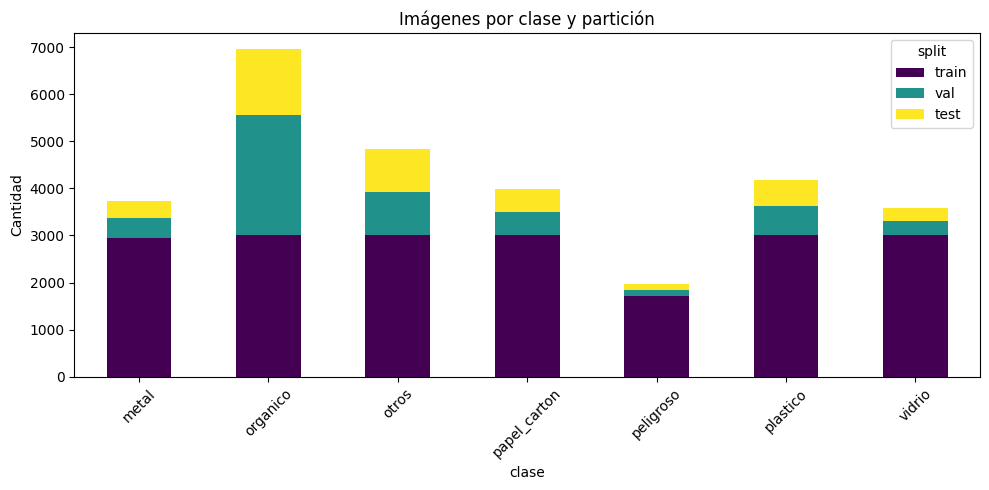

Ratio de desbalance (train): 1.7:1

Origen de las imágenes por partición:


split,test,train,val
origen,,,
ds1,1356,8733,1341
ds2,1444,4855,2862
rw,710,3329,713
taco,552,2761,556


Origen de las imágenes de TRAIN por clase:


origen,ds1,ds2,rw,taco
clase,,,,
metal,1053,1044,553,303
organico,181,2217,594,8
otros,1783,0,570,647
papel_carton,1180,870,673,277
peligroso,1389,334,0,2
plastico,554,390,645,1411
vidrio,2593,0,294,113


In [ ]:
tabla = df.groupby(['clase', 'split']).size().unstack(fill_value=0)
tabla['total'] = tabla.sum(axis=1)
display(tabla)
tabla[['train', 'val', 'test']].plot(kind='bar', stacked=True, figsize=(10, 5), colormap='viridis')
plt.title('Imágenes por clase y partición'); plt.ylabel('Cantidad'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

cnt = df[df.split == 'train']['clase'].value_counts()
print(f"Ratio de desbalance (train): {cnt.max()/cnt.min():.1f}:1")
print("\nOrigen de las imágenes por partición:"); display(df.groupby(['origen', 'split']).size().unstack(fill_value=0))
print("Origen de las imágenes de TRAIN por clase:"); display(df[df.split == 'train'].groupby(['clase', 'origen']).size().unstack(fill_value=0))

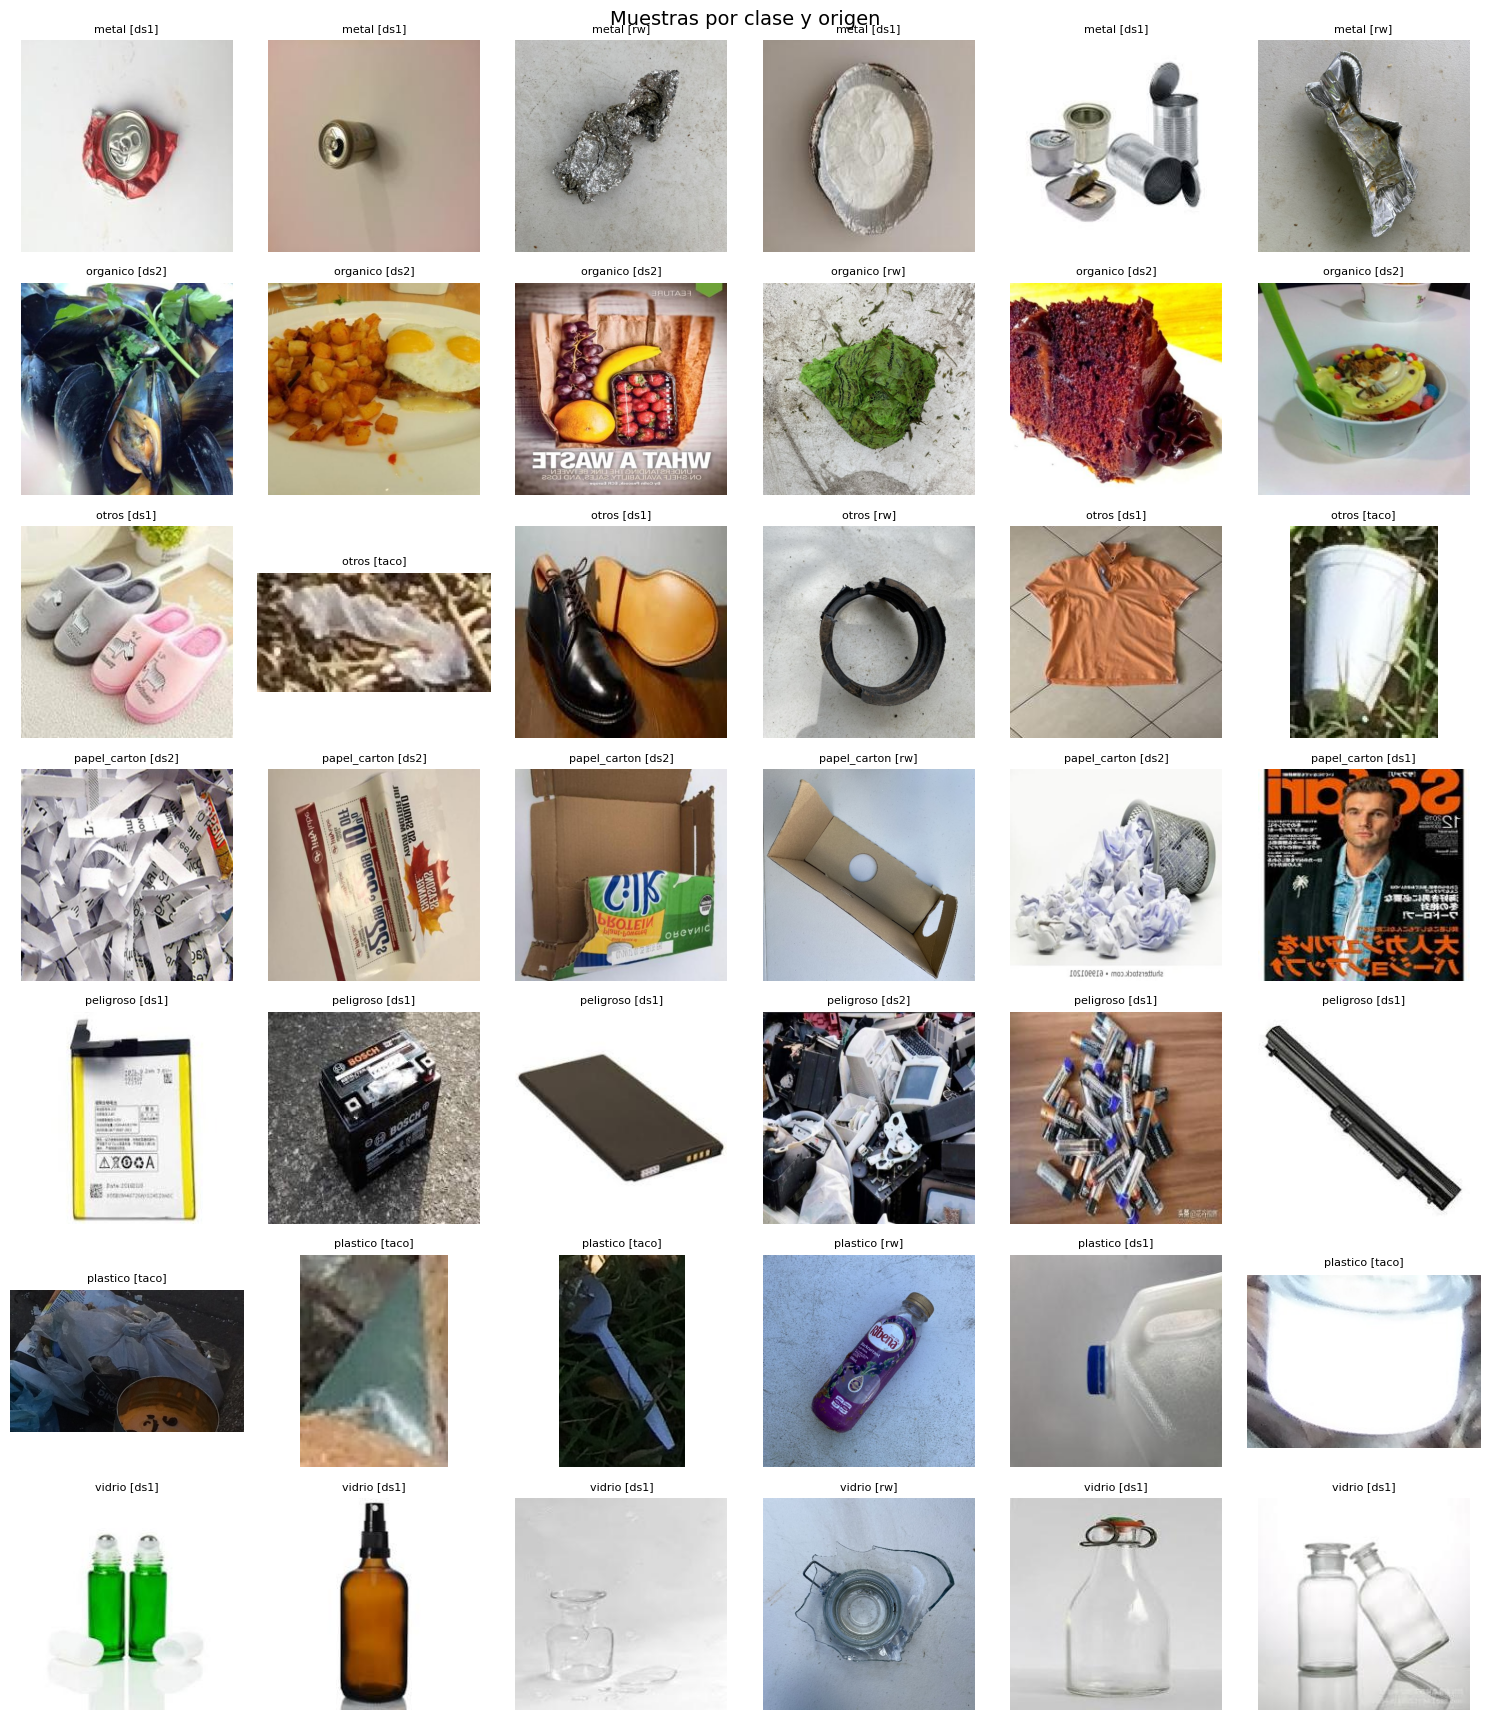

In [ ]:
# Muestras por clase (con su origen)
nombres = sorted(df.clase.unique())
fig, axes = plt.subplots(len(nombres), 6, figsize=(15, 2.5*len(nombres)))
for i, c in enumerate(nombres):
    s = df[(df.clase == c) & (df.split == 'train')]
    s = s.sample(min(6, len(s)), random_state=SEED)
    for j in range(6):
        axes[i, j].axis('off')
        if j < len(s):
            axes[i, j].imshow(Image.open(s.iloc[j].path)); axes[i, j].set_title(f"{c} [{s.iloc[j].origen}]", fontsize=8)
plt.suptitle('Muestras por clase y origen', fontsize=14); plt.tight_layout(); plt.show()

## 🔄 Fase 3: Preprocesamiento y Data Augmentation
- Las imágenes se leen **por lotes desde disco** (`image_dataset_from_directory`): no hace falta más RAM.
- `crop_to_aspect_ratio=True` recorta el **centro cuadrado** en vez de estirar la imagen (los objetos no se deforman). La app hace el mismo recorte al predecir.
- El augmentation va dentro del modelo y solo se aplica en entrenamiento.

In [ ]:
CLASS_NAMES = sorted(df.clase.unique())
NUM_CLASSES = len(CLASS_NAMES)
common = dict(image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical',
              class_names=CLASS_NAMES, follow_links=True, crop_to_aspect_ratio=True)
train_raw = tf.keras.utils.image_dataset_from_directory(f"{UNI}/train", shuffle=True, seed=SEED, **common)
val_raw   = tf.keras.utils.image_dataset_from_directory(f"{UNI}/val",   shuffle=False, **common)
test_raw  = tf.keras.utils.image_dataset_from_directory(f"{UNI}/test",  shuffle=False, **common)
print("Clases:", CLASS_NAMES)

train_ds = train_raw.prefetch(AUTOTUNE)   # image_dataset_from_directory ya baraja en cada época
val_ds   = val_raw.prefetch(AUTOTUNE)
test_ds  = test_raw.prefetch(AUTOTUNE)

# Pesos de clase (calculados desde la tabla, sin leer imágenes)
y_train_idx = df[df.split == 'train']['clase'].map(CLASS_NAMES.index).values
cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_train_idx)
CLASS_WEIGHTS = {i: w for i, w in enumerate(cw)}
print("Class weights:", {CLASS_NAMES[i]: round(w, 2) for i, w in CLASS_WEIGHTS.items()})
print("Baseline aleatorio:", f"{1/NUM_CLASSES:.1%}", "| Baseline clase mayoritaria:", f"{np.bincount(y_train_idx).max()/len(y_train_idx):.1%}")

Found 19678 files belonging to 7 classes.
Found 5472 files belonging to 7 classes.
Found 4062 files belonging to 7 classes.
Clases: ['metal', 'organico', 'otros', 'papel_carton', 'peligroso', 'plastico', 'vidrio']
Class weights: {'metal': np.float64(0.95), 'organico': np.float64(0.94), 'otros': np.float64(0.94), 'papel_carton': np.float64(0.94), 'peligroso': np.float64(1.63), 'plastico': np.float64(0.94), 'vidrio': np.float64(0.94)}
Baseline aleatorio: 14.3% | Baseline clase mayoritaria: 15.2%


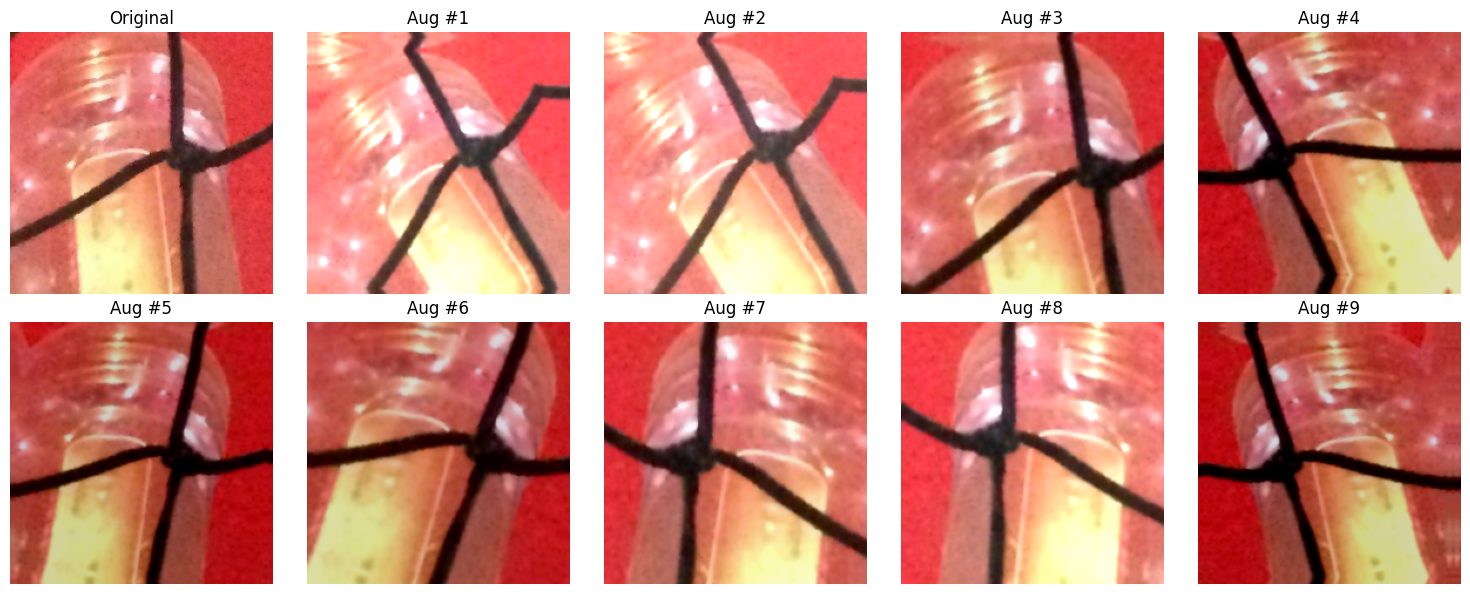

In [ ]:
def make_augmentation():
    return tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomTranslation(0.08, 0.08),
        layers.RandomZoom((-0.2, 0.1)),
        layers.RandomContrast(0.2),
        layers.RandomBrightness(0.2, value_range=(0, 255)),
    ], name='augmentation')

aug = make_augmentation()
imgs, _ = next(iter(train_raw))
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes[0, 0].imshow(imgs[0].numpy().astype('uint8')); axes[0, 0].set_title('Original'); axes[0, 0].axis('off')
for i in range(1, 10):
    a = aug(imgs[0:1], training=True)[0].numpy().clip(0, 255).astype('uint8')
    axes[i//5, i % 5].imshow(a); axes[i//5, i % 5].set_title(f'Aug #{i}'); axes[i//5, i % 5].axis('off')
plt.tight_layout(); plt.show()

## 🏗️ Fase 4: Diseño de los 3 modelos

| # | Modelo | Estrategia |
|---|---|---|
| 1 | **CNN propia** | Entrenada desde cero (bloques residuales) |
| 2 | **MobileNetV2 – Feature Extraction** | **Backbone congelado**: solo se entrena el clasificador |
| 3 | **MobileNetV2 – Fine-Tuning** | **Congelamiento parcial de capas**: warm-up y luego se descongelan las últimas N capas con LR bajo |

### Modelo 1: CNN propia (desde cero)

In [ ]:
tf.keras.backend.clear_session(); gc.collect()

def residual_block(x, filters, stride=1):
    shortcut = x
    x = layers.Conv2D(filters, 3, strides=stride, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding='same', use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    return layers.Activation('relu')(layers.Add()([x, shortcut]))

def build_cnn_propia(num_classes):
    inp = layers.Input(shape=(*IMG_SIZE, 3))
    x = make_augmentation()(inp)
    x = layers.Rescaling(1./255)(x)
    x = layers.Conv2D(32, 7, strides=2, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)
    for f, s in [(32, 1), (64, 2), (128, 2), (256, 2)]:
        x = residual_block(x, f, s)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inp, out, name='cnn_propia')

model_cnn = build_cnn_propia(NUM_CLASSES)
model_cnn.summary()

Model: "cnn_propia"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ augmentation[0][… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │      4,704 │ rescaling[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 56, 56,    │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 56, 56,    │      9,216 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │      9,216 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 56, 56,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 28, 28,    │     18,432 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 28, 28,    │          0 │ batch_normalizat

 Total params: 1,266,919 (4.83 MB)

 Trainable params: 1,264,039 (4.82 MB)

 Non-trainable params: 2,880 (11.25 KB)

### Modelo 2: MobileNetV2 — Feature Extraction (backbone congelado)

In [ ]:
def build_mobilenet(num_classes):
    base = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False, input_shape=(*IMG_SIZE, 3))
    base.trainable = False                       # backbone congelado
    inp = layers.Input(shape=(*IMG_SIZE, 3))
    x = make_augmentation()(inp)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)   # escala a [-1, 1]
    x = base(x, training=False)                  # BatchNorm del backbone en modo inferencia (importante)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inp, out, name='mobilenetv2'), base

model_fe, base_fe = build_mobilenet(NUM_CLASSES)
model_fe._name = 'mobilenetv2_feature_extraction'
tr = sum(tf.size(w).numpy() for w in model_fe.trainable_weights)
print(f"Params totales: {model_fe.count_params():,} | entrenables: {tr:,} ({tr/model_fe.count_params():.1%})")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Params totales: 2,427,975 | entrenables: 167,431 (6.9%)


### Modelo 3: MobileNetV2 — Fine-Tuning (congelamiento parcial de capas)

In [ ]:
# Se construye igual que el modelo 2; el descongelamiento parcial ocurre en la Fase 5.3
model_ft, base_ft = build_mobilenet(NUM_CLASSES)
model_ft._name = 'mobilenetv2_fine_tuning'
print("Capas del backbone:", len(base_ft.layers))
print(f"\n{'Modelo':<35}{'Params':>12}{'Tamaño aprox (MB)':>20}"); print('-'*67)
for m in [model_cnn, model_fe, model_ft]:
    print(f"{m.name:<35}{m.count_params():>12,}{m.count_params()*4/1024/1024:>20.1f}")

Capas del backbone: 154

Modelo                                   Params   Tamaño aprox (MB)
-------------------------------------------------------------------
cnn_propia                            1,266,919                 4.8
mobilenetv2                           2,427,975                 9.3
mobilenetv2                           2,427,975                 9.3


## 🏋️ Fase 5: Entrenamiento con callbacks
Todos los modelos usan `ModelCheckpoint`, `EarlyStopping`, `ReduceLROnPlateau` (los tres sobre `val_loss`, criterio consistente), `CSVLogger` y `class_weight`.

In [ ]:
def get_callbacks(name, patience_es=6, patience_lr=3):
    d = f"/content/runs/{name}_{STAMP}"; os.makedirs(d, exist_ok=True)
    return [
        tf.keras.callbacks.ModelCheckpoint(f"{d}/best.keras", monitor='val_loss', mode='min', save_best_only=True, verbose=0),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=patience_lr, min_lr=1e-7, verbose=1),
        tf.keras.callbacks.CSVLogger(f"{d}/log.csv"),
    ], d

def compile_model(m, lr):
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),
              loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05), metrics=['accuracy'])

### 5.1 Modelo 1 — CNN propia

In [ ]:
compile_model(model_cnn, 1e-3)
cbs, dir_cnn = get_callbacks('cnn_propia', patience_es=8, patience_lr=4)
t0 = time.time()
hist_cnn = model_cnn.fit(train_ds, validation_data=val_ds, epochs=40, class_weight=CLASS_WEIGHTS, callbacks=cbs)
time_cnn = time.time() - t0
print(f"Tiempo: {time_cnn/60:.1f} min")

Epoch 1/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 76s 88ms/step - accuracy: 0.3669 - loss: 1.6832 - val_accuracy: 0.5097 - val_loss: 1.5313 - learning_rate: 0.0010
Epoch 2/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 51s 83ms/step - accuracy: 0.4421 - loss: 1.5332 - val_accuracy: 0.5671 - val_loss: 1.4058 - learning_rate: 0.0010
Epoch 3/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 52s 85ms/step - accuracy: 0.4829 - loss: 1.4537 - val_accuracy: 0.5747 - val_loss: 1.3374 - learning_rate: 0.0010
Epoch 4/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 51s 83ms/step - accuracy: 0.5129 - loss: 1.3960 - val_accuracy: 0.5530 - val_loss: 1.3930 - learning_rate: 0.0010
Epoch 5/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 53s 86ms/step - accuracy: 0.5331 - loss: 1.3548 - val_accuracy: 0.6106 - val_loss: 1.2131 - learning_rate: 0.0010
Epoch 6/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 82s 85ms/step - accuracy: 0.5463 - loss: 1.3211 - val_accuracy: 0.6148 - val_loss: 1.2307 - learning_rate: 0.0010
Epoch 7/40
615/615 ━━━━━━━━━━━━━━━━━━━━ 84s 88ms/step - accuracy: 0.5578 - l

### 5.2 Modelo 2 — Feature Extraction (backbone congelado)

In [ ]:
gc.collect()
compile_model(model_fe, 1e-3)
cbs, dir_fe = get_callbacks('mobilenet_fe', patience_es=4, patience_lr=2)
t0 = time.time()
hist_fe = model_fe.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=CLASS_WEIGHTS, callbacks=cbs)
time_fe = time.time() - t0
print(f"Tiempo: {time_fe/60:.1f} min")

Epoch 1/15
615/615 ━━━━━━━━━━━━━━━━━━━━ 61s 84ms/step - accuracy: 0.7167 - loss: 0.9831 - val_accuracy: 0.8772 - val_loss: 0.6292 - learning_rate: 0.0010
Epoch 2/15
615/615 ━━━━━━━━━━━━━━━━━━━━ 51s 83ms/step - accuracy: 0.7889 - loss: 0.7771 - val_accuracy: 0.8893 - val_loss: 0.5755 - learning_rate: 0.0010
Epoch 3/15
615/615 ━━━━━━━━━━━━━━━━━━━━ 50s 82ms/step - accuracy: 0.8142 - loss: 0.7185 - val_accuracy: 0.8925 - val_loss: 0.5575 - learning_rate: 0.0010
Epoch 4/15
615/615 ━━━━━━━━━━━━━━━━━━━━ 51s 83ms/step - accuracy: 0.8243 - loss: 0.6894 - val_accuracy: 0.8960 - val_loss: 0.5523 - learning_rate: 0.0010
Epoch 5/15
615/615 ━━━━━━━━━━━━━━━━━━━━ 51s 83ms/step - accuracy: 0.8373 - loss: 0.6667 - val_accuracy: 0.9015 - val_loss: 0.5379 - learning_rate: 0.0010
Epoch 6/15
615/615 ━━━━━━━━━━━━━━━━━━━━ 50s 81ms/step - accuracy: 0.8430 - loss: 0.6511 - val_accuracy: 0.9011 - val_loss: 0.5387 - learning_rate: 0.0010
Epoch 7/15
615/615 ━━━━━━━━━━━━━━━━━━━━ 84s 84ms/step - accuracy: 0.8504 - l

### 5.3 Modelo 3 — Fine-Tuning (congelamiento parcial de capas, protocolo de 2 fases)
**Fase 1:** warm-up con el backbone congelado. **Fase 2:** se descongelan las últimas `N_UNFREEZE` capas y se recompila con LR 100× menor.

In [ ]:
gc.collect()
# FASE 1: warm-up del clasificador (backbone congelado)
compile_model(model_ft, 1e-3)
cbs1, dir_ft1 = get_callbacks('mobilenet_ft_fase1', patience_es=3, patience_lr=2)
t0 = time.time()
hist_ft1 = model_ft.fit(train_ds, validation_data=val_ds, epochs=6, class_weight=CLASS_WEIGHTS, callbacks=cbs1)

# FASE 2: congelamiento parcial -> se descongelan solo las últimas N capas del backbone
N_UNFREEZE = 40     # puedes experimentar: 20, 40, 60...
base_ft.trainable = True
for layer in base_ft.layers[:-N_UNFREEZE]:
    layer.trainable = False
frozen = sum(1 for l in base_ft.layers if not l.trainable)
print(f"Capas congeladas: {frozen} | descongeladas: {len(base_ft.layers)-frozen}")
tr = sum(tf.size(w).numpy() for w in model_ft.trainable_weights)
print(f"Params entrenables ahora: {tr:,}")

compile_model(model_ft, 1e-5)   # recompilar es obligatorio al cambiar trainable
cbs2, dir_ft = get_callbacks('mobilenet_ft_fase2', patience_es=5, patience_lr=2)
hist_ft2 = model_ft.fit(train_ds, validation_data=val_ds, epochs=20, initial_epoch=len(hist_ft1.history['loss']),
                        class_weight=CLASS_WEIGHTS, callbacks=cbs2)
time_ft = time.time() - t0
print(f"Tiempo total (2 fases): {time_ft/60:.1f} min")

Epoch 1/6
615/615 ━━━━━━━━━━━━━━━━━━━━ 58s 85ms/step - accuracy: 0.7134 - loss: 0.9995 - val_accuracy: 0.8730 - val_loss: 0.6127 - learning_rate: 0.0010
Epoch 2/6
615/615 ━━━━━━━━━━━━━━━━━━━━ 49s 80ms/step - accuracy: 0.7895 - loss: 0.7760 - val_accuracy: 0.8863 - val_loss: 0.5727 - learning_rate: 0.0010
Epoch 3/6
615/615 ━━━━━━━━━━━━━━━━━━━━ 82s 81ms/step - accuracy: 0.8116 - loss: 0.7202 - val_accuracy: 0.8924 - val_loss: 0.5580 - learning_rate: 0.0010
Epoch 4/6
615/615 ━━━━━━━━━━━━━━━━━━━━ 82s 82ms/step - accuracy: 0.8282 - loss: 0.6921 - val_accuracy: 0.9017 - val_loss: 0.5417 - learning_rate: 0.0010
Epoch 5/6
615/615 ━━━━━━━━━━━━━━━━━━━━ 51s 83ms/step - accuracy: 0.8367 - loss: 0.6700 - val_accuracy: 0.9035 - val_loss: 0.5411 - learning_rate: 0.0010
Epoch 6/6
615/615 ━━━━━━━━━━━━━━━━━━━━ 50s 81ms/step - accuracy: 0.8413 - loss: 0.6589 - val_accuracy: 0.9037 - val_loss: 0.5425 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.
Capas congeladas: 114 |

### 5.4 Curvas de aprendizaje

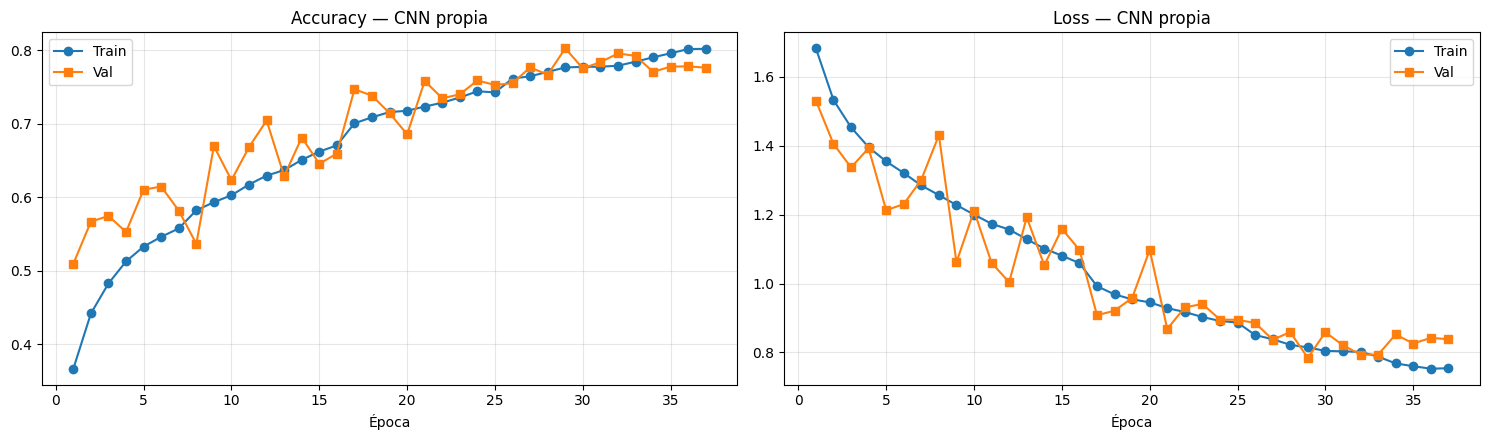

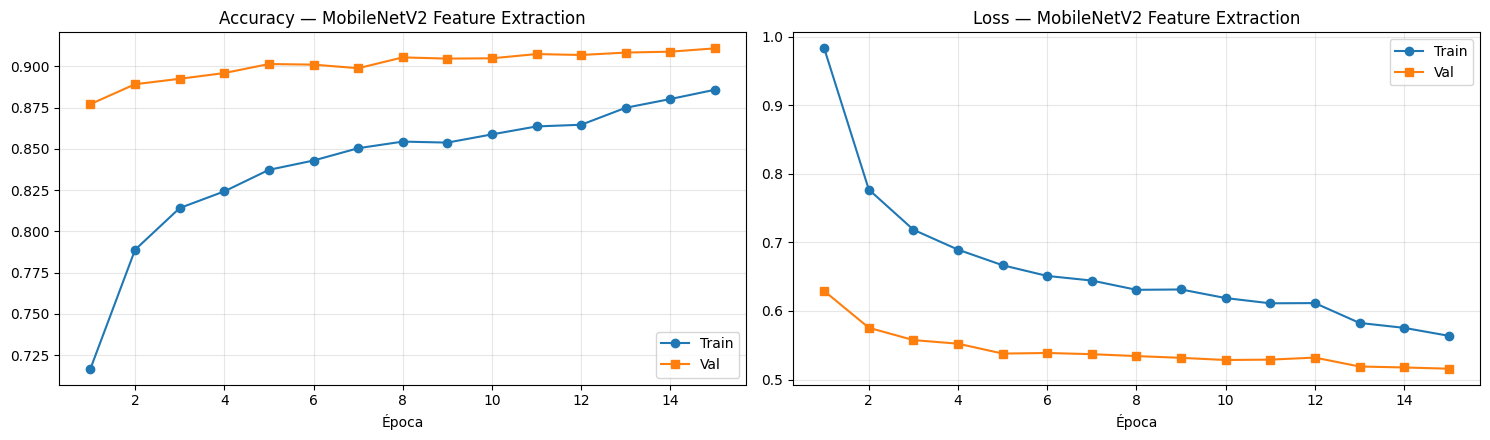

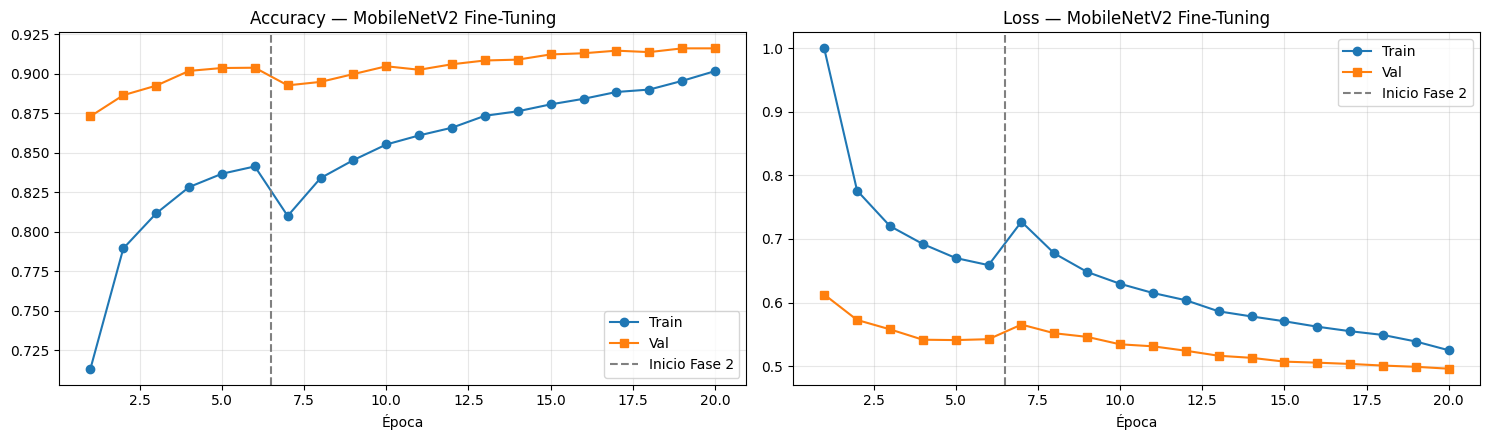

In [ ]:
def plot_hist(hists, title, phase_split=None):
    acc  = sum([h.history['accuracy'] for h in hists], []);     vacc  = sum([h.history['val_accuracy'] for h in hists], [])
    loss = sum([h.history['loss'] for h in hists], []);         vloss = sum([h.history['val_loss'] for h in hists], [])
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
    for a, (tr, va, nm) in zip(ax, [(acc, vacc, 'Accuracy'), (loss, vloss, 'Loss')]):
        a.plot(range(1, len(tr)+1), tr, 'o-', label='Train'); a.plot(range(1, len(va)+1), va, 's-', label='Val')
        if phase_split: a.axvline(phase_split+0.5, color='gray', ls='--', label='Inicio Fase 2')
        a.set_title(f'{nm} — {title}'); a.set_xlabel('Época'); a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()

plot_hist([hist_cnn], 'CNN propia')
plot_hist([hist_fe], 'MobileNetV2 Feature Extraction')
plot_hist([hist_ft1, hist_ft2], 'MobileNetV2 Fine-Tuning', phase_split=len(hist_ft1.history['loss']))

### 📝 Análisis de las curvas

**¿Qué modelo ajusta mejor?** Los dos modelos con MobileNetV2 ajustan claramente mejor que la CNN propia. La CNN propia termina su mejor época (la 29) con val_accuracy ≈ 0.80 y val_loss ≈ 0.78. Feature Extraction llega a val_accuracy ≈ 0.911 y val_loss ≈ 0.516, y Fine-Tuning a val_accuracy ≈ 0.916 y val_loss ≈ 0.496. Los pesos preentrenados en ImageNet le dan a MobileNetV2 una ventaja grande desde la primera época (≈ 0.87 de val_accuracy, frente a ≈ 0.51 de la CNN propia).

**¿Hay overfitting?** No de forma importante en ninguno de los tres modelos:
- En los tres, la accuracy de *train* es igual o menor que la de *val* (CNN propia: 0.78 vs 0.80 en la mejor época; Feature Extraction: 0.886 vs 0.911; Fine-Tuning: 0.902 vs 0.916). Esto es normal: el *train* se mide con augmentation, dropout y label smoothing activos, y la *val* no.
- La CNN propia es la más inestable: su val_loss oscila mucho (por ejemplo, 1.43 en la época 8 y 1.06 en la 9) y recién se estabiliza cuando `ReduceLROnPlateau` baja el LR. Se detuvo por `EarlyStopping` en la época 37 y restauró los pesos de la 29. Hacia el final el *train* sigue subiendo (≈ 0.80) mientras la *val* se estanca (≈ 0.78), señal de que empezaba a sobreajustar.
- Feature Extraction y Fine-Tuning tienen curvas suaves y val_loss decreciente.

**¿Qué efecto tuvo la Fase 2 del fine-tuning?** La Fase 1 (warm-up con backbone congelado) se comportó igual que Feature Extraction (val_accuracy ≈ 0.90, mejor val_loss ≈ 0.541 en la época 5). Al descongelar las últimas 40 capas con LR = 1e-5, el *train* bajó al inicio (≈ 0.81) porque cambiaron los pesos que antes estaban fijos. Luego subió de forma sostenida hasta 0.902. En validación la val_loss mejoró de 0.541 a 0.496 y la val_accuracy de 0.904 a 0.916. La mejora es real pero modesta (≈ +1 punto de accuracy sobre Feature Extraction). Además, la val_loss seguía bajando en la época 20, así que con más épocas podría mejorar un poco más.

## 📊 Fase 6: Evaluación (sobre el conjunto de **test**, que ningún modelo vio)
Además de las métricas globales, se mide el rendimiento **por origen** (`ds1`, `ds2`, `rw`, `taco`): así se ve si el modelo rinde igual en fotos de estudio que en residuos reales.

In [ ]:
orig_test = np.array([os.path.basename(p).split('_')[0] for p in test_raw.file_paths])

def evaluate(model, name):
    probs = model.predict(test_ds, verbose=0)
    y_pred = probs.argmax(1)
    y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])
    rep = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True, zero_division=0)
    por_origen = {}
    for o in sorted(set(orig_test)):
        mk = orig_test == o
        por_origen[o] = dict(n=int(mk.sum()), acc=accuracy_score(y_true[mk], y_pred[mk]))
    return dict(name=name, probs=probs, y_pred=y_pred, y_true=y_true, rep=rep, por_origen=por_origen)

EVAL = {}
for nm, m in [('CNN propia', model_cnn), ('MobileNetV2 FE', model_fe), ('MobileNetV2 Fine-Tuning', model_ft)]:
    EVAL[nm] = evaluate(m, nm)
    print(f"\n===== {nm} =====")
    print(classification_report(EVAL[nm]['y_true'], EVAL[nm]['y_pred'], target_names=CLASS_NAMES, digits=4, zero_division=0))
    print("Accuracy por origen:", {o: f"{v['acc']:.3f} (n={v['n']})" for o, v in EVAL[nm]['por_origen'].items()})


===== CNN propia =====
              precision    recall  f1-score   support

       metal     0.5772    0.6658    0.6183       365
    organico     0.8982    0.9302    0.9139      1404
       otros     0.7658    0.7243    0.7445       903
papel_carton     0.8405    0.6506    0.7335       478
   peligroso     0.6014    0.7807    0.6794       114
    plastico     0.6071    0.6364    0.6214       539
      vidrio     0.7400    0.7143    0.7269       259

    accuracy                         0.7708      4062
   macro avg     0.7186    0.7289    0.7197      4062
weighted avg     0.7761    0.7708    0.7711      4062

Accuracy por origen: {np.str_('ds1'): '0.770 (n=1356)', np.str_('ds2'): '0.904 (n=1444)', np.str_('rw'): '0.758 (n=710)', np.str_('taco'): '0.442 (n=552)'}

===== MobileNetV2 FE =====
              precision    recall  f1-score   support

       metal     0.8462    0.7534    0.7971       365
    organico     0.9793    0.9779    0.9786      1404
       otros     0.9160    0.893

### 6.2 Matrices de confusión

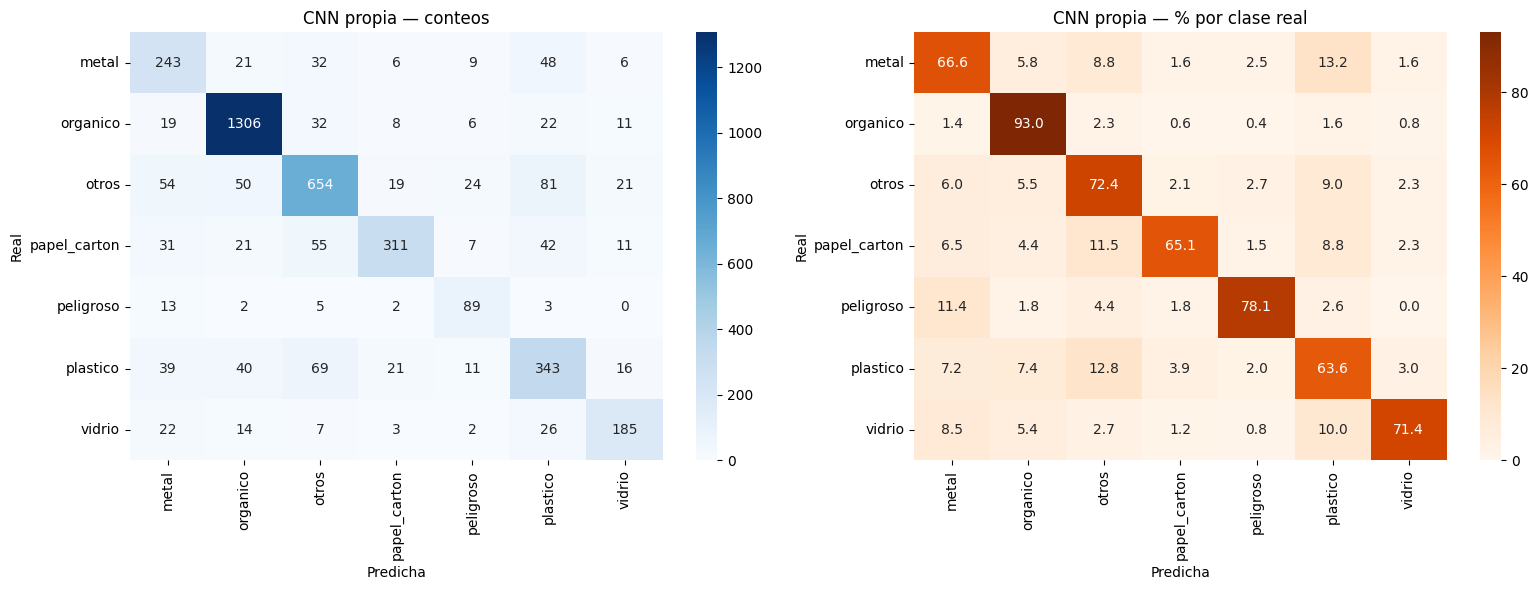

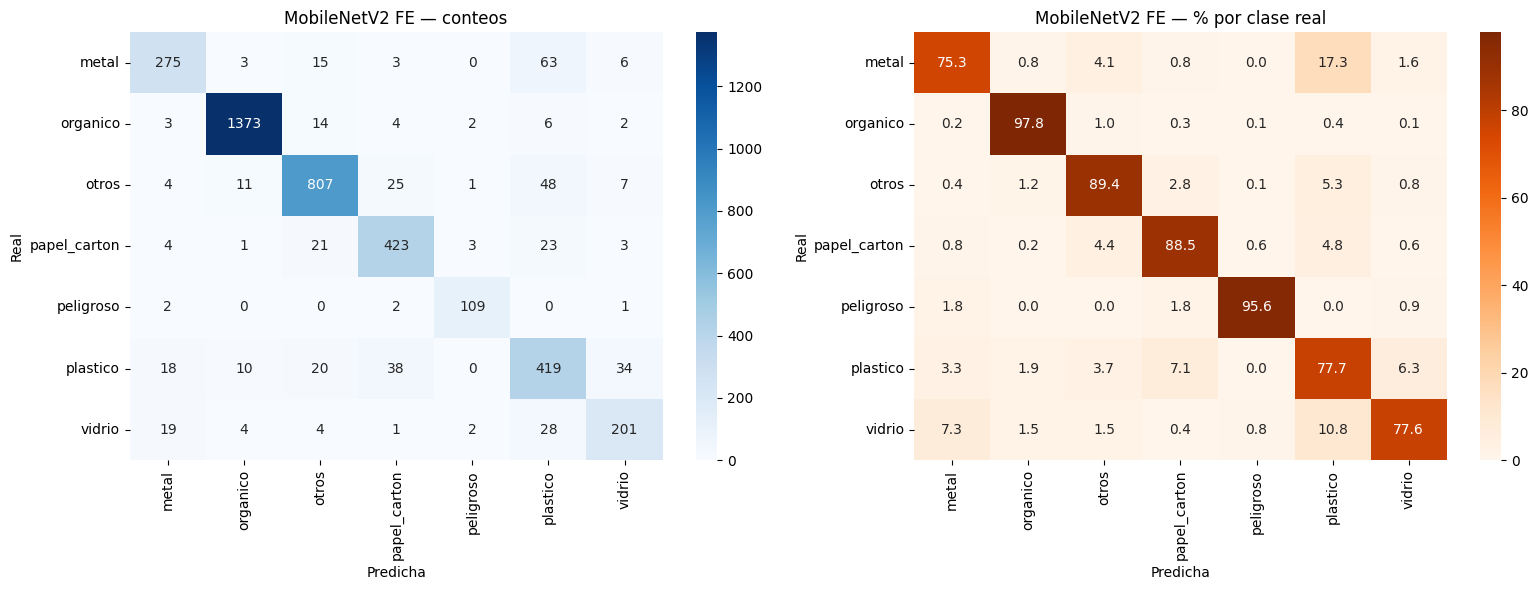

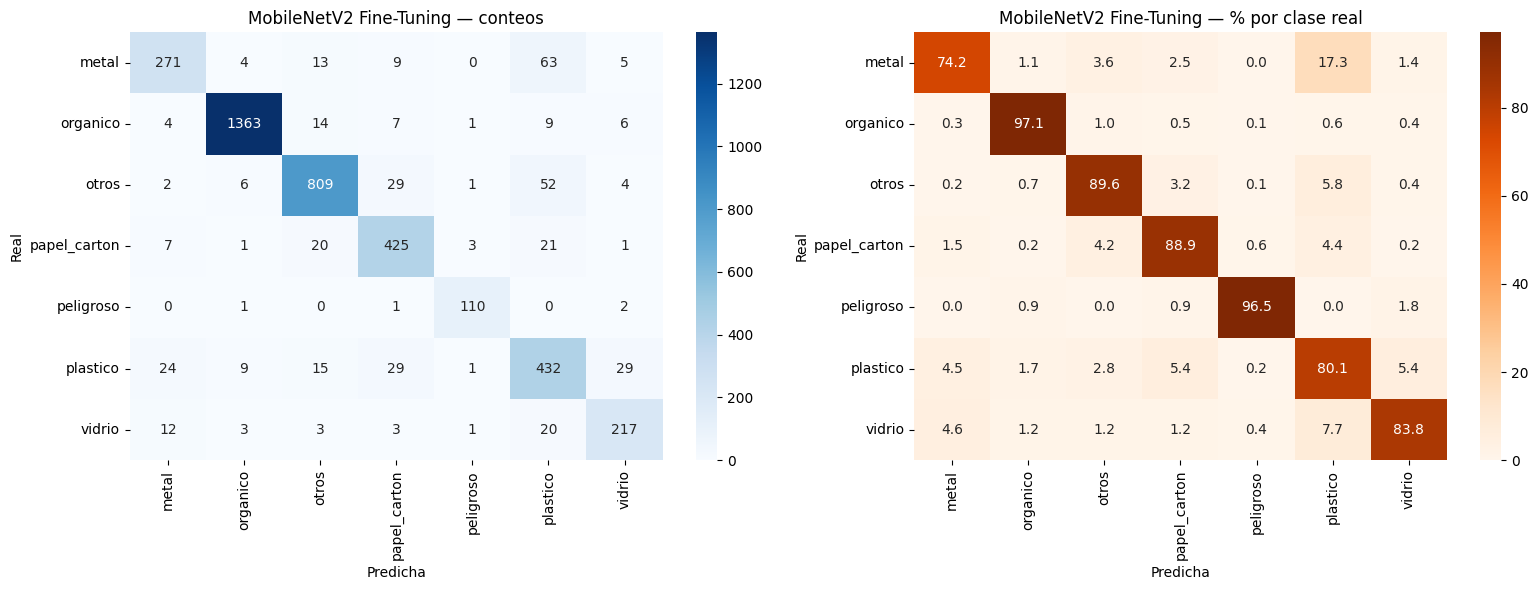

In [ ]:
def plot_cm(ev):
    cm = confusion_matrix(ev['y_true'], ev['y_pred'], labels=range(NUM_CLASSES))
    cmp = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0])
    sns.heatmap(cmp, annot=True, fmt='.1f', cmap='Oranges', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1])
    ax[0].set_title(f"{ev['name']} — conteos"); ax[1].set_title(f"{ev['name']} — % por clase real")
    for a in ax: a.set_xlabel('Predicha'); a.set_ylabel('Real')
    plt.tight_layout(); plt.show()

for ev in EVAL.values(): plot_cm(ev)

## 🔬 Fase 7: Análisis de errores

In [ ]:
best_name = max(EVAL, key=lambda k: EVAL[k]['rep']['macro avg']['f1-score'])
ev = EVAL[best_name]; print("Mejor modelo por F1 macro:", best_name)

cm = confusion_matrix(ev['y_true'], ev['y_pred'], labels=range(NUM_CLASSES)); np.fill_diagonal(cm, 0)
errs = sorted([(CLASS_NAMES[i], CLASS_NAMES[j], cm[i, j]) for i in range(NUM_CLASSES)
               for j in range(NUM_CLASSES) if cm[i, j] > 0], key=lambda x: -x[2])[:8]
print(f"\n{'Real':<18}{'Predicha':<18}{'Errores':>8}"); print('-'*44)
for r, p, n in errs: print(f"{r:<18}{p:<18}{n:>8}")

Mejor modelo por F1 macro: MobileNetV2 Fine-Tuning

Real              Predicha           Errores
--------------------------------------------
metal             plastico                63
otros             plastico                52
otros             papel_carton            29
plastico          papel_carton            29
plastico          vidrio                  29
plastico          metal                   24
papel_carton      plastico                21
papel_carton      otros                   20


Errores: 435 de 4062 (10.7%)


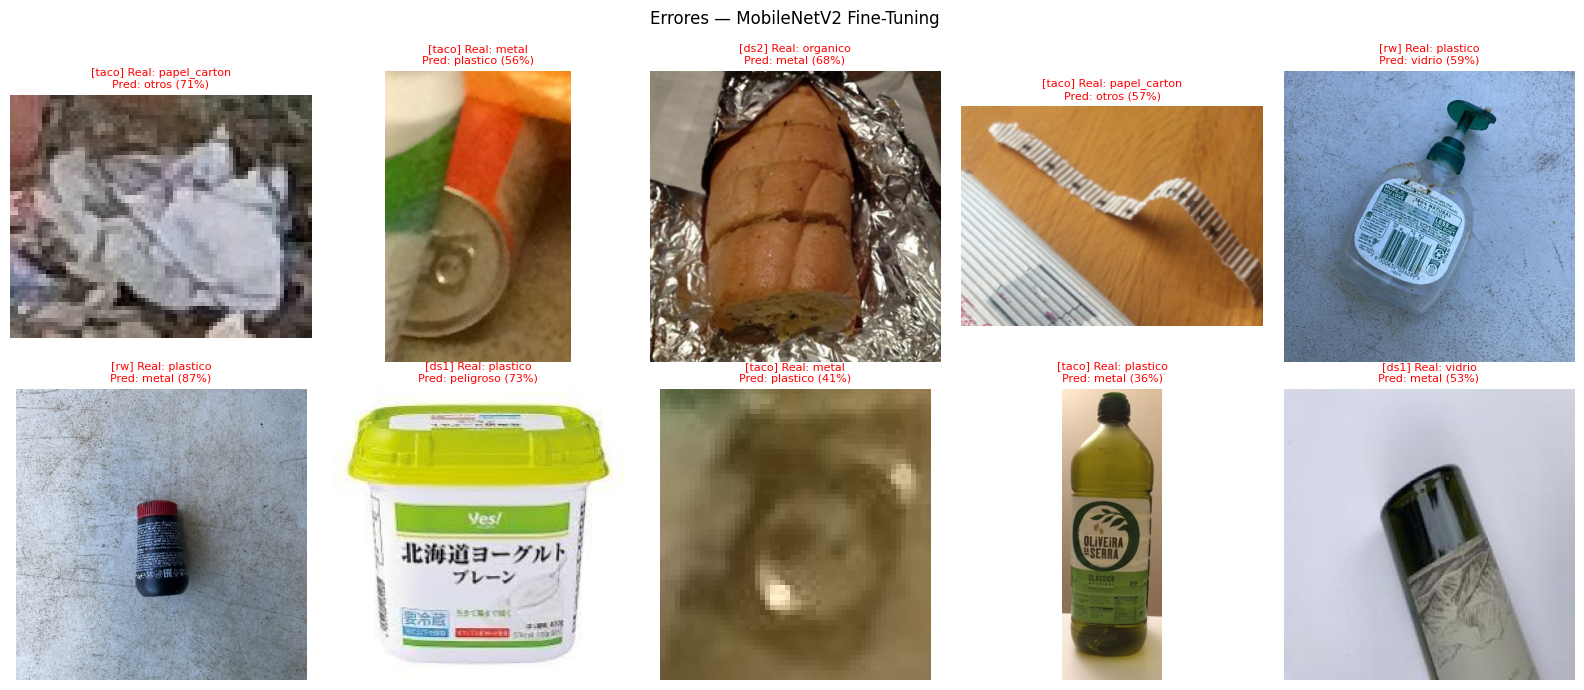

In [ ]:
files = np.array(test_raw.file_paths)
wrong = np.where(ev['y_true'] != ev['y_pred'])[0]
print(f"Errores: {len(wrong)} de {len(ev['y_true'])} ({len(wrong)/len(ev['y_true']):.1%})")
sel = np.random.RandomState(SEED).choice(wrong, size=min(10, len(wrong)), replace=False)
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for a, k in zip(axes.ravel(), sel):
    a.imshow(Image.open(files[k])); a.axis('off')
    a.set_title(f"[{orig_test[k]}] Real: {CLASS_NAMES[ev['y_true'][k]]}\nPred: {CLASS_NAMES[ev['y_pred'][k]]} ({ev['probs'][k].max():.0%})", fontsize=8, color='red')
plt.suptitle(f'Errores — {best_name}'); plt.tight_layout(); plt.show()

### 📝 Tabla de mejoras

| Hallazgo (par confundido) | Posible causa | Acción correctiva propuesta |
|---|---|---|
| **metal → plástico** (63 errores, ≈17 % de las imágenes de metal) | Latas y envases metálicos con etiquetas de colores, reflejos o sucios se parecen a envases de plástico; además, `plastico` es una de las clases con menor precisión (≈0.72) | Agregar más fotos reales de latas y metales en distintos fondos e iluminación; aumentar el *augmentation* de brillo y contraste; probar `N_UNFREEZE` mayor (60 o más) para que el modelo aprenda texturas finas |
| **otros → plástico** (52) y **otros → papel_carton** (29) | `otros` es una clase heterogénea (ropa, zapatos, basura mixta, envases de espuma) y comparte textura y color con plástico y papel | Revisar el mapeo de `otros` y limpiar etiquetas dudosas; agregar ejemplos más variados; evaluar dividir `otros` en subclases o usar un umbral de confianza para derivar a revisión |
| **plástico ↔ papel_carton / vidrio / metal** (29, 29, 24 y 21 en sentido contrario) | `plastico` es la clase con peor F1 (≈0.76). Sus fotos vienen sobre todo de TACO (1 411 de 3 000 en *train*), con fondos desordenados, objetos pequeños y transparencias confundibles con vidrio | Balancear mejor las fuentes dentro de cada clase; añadir más plástico de otras fuentes limpias; usar *augmentation* de recorte y zoom; probar un modelo con mayor resolución de entrada |
| **Brecha por origen**: TACO ≈0.59 vs ds1/ds2 ≈0.95–0.97 | Los recortes de TACO son pequeños, con poco contexto y baja resolución; además algunas clases casi no tienen ejemplos TACO en *train* (organico: 8, peligroso: 2) | Capturar un conjunto propio con la cámara del ESP32-CAM o del celular, y reentrenar o hacer fine-tuning con esas fotos; filtrar recortes demasiado pequeños |

## 📈 Fase 8: Comparación sistemática de modelos

,Modelo,Test Accuracy,F1 macro,Precision macro,Recall macro,Acc ds1,Acc ds2,Acc rw,Acc taco,Params,Tamaño .keras (MB),Tiempo (min)
0,CNN propia,0.7708,0.7197,0.7186,0.7289,0.770,0.904,0.758,0.442,"1,266,919",14.7,34.5
1,MobileNetV2 FE,0.8880,0.8601,0.8616,0.8599,0.946,0.979,0.823,0.592,"2,427,975",11.1,15.0
2,MobileNetV2 Fine-Tuning,0.8929,0.8697,0.8694,0.8718,0.954,0.970,0.855,0.591,"2,427,975",24.0,23.0


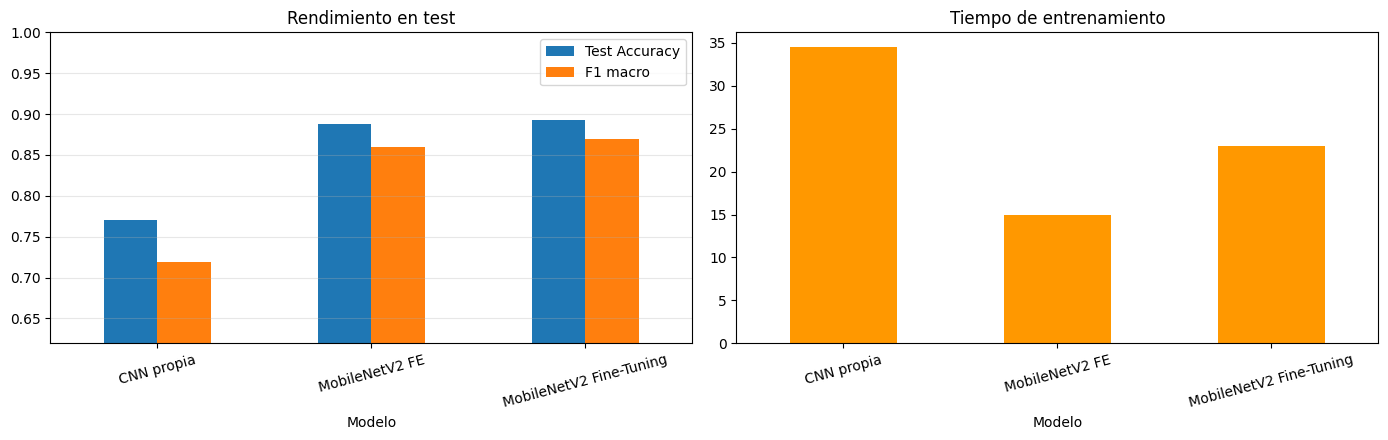

In [ ]:
def model_size_mb(path): return os.path.getsize(path)/1024/1024
rows = []
for nm, m, d, t in [('CNN propia', model_cnn, dir_cnn, time_cnn),
                    ('MobileNetV2 FE', model_fe, dir_fe, time_fe),
                    ('MobileNetV2 Fine-Tuning', model_ft, dir_ft, time_ft)]:
    r = EVAL[nm]['rep']
    fila = {'Modelo': nm,
            'Test Accuracy': round(r['accuracy'], 4),
            'F1 macro': round(r['macro avg']['f1-score'], 4),
            'Precision macro': round(r['macro avg']['precision'], 4),
            'Recall macro': round(r['macro avg']['recall'], 4)}
    for o, v in EVAL[nm]['por_origen'].items(): fila[f'Acc {o}'] = round(v['acc'], 3)
    fila.update({'Params': f"{m.count_params():,}", 'Tamaño .keras (MB)': round(model_size_mb(f"{d}/best.keras"), 1),
                 'Tiempo (min)': round(t/60, 1)})
    rows.append(fila)
df_res = pd.DataFrame(rows); display(df_res)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
df_res.plot(x='Modelo', y=['Test Accuracy', 'F1 macro'], kind='bar', ax=ax[0], ylim=(max(0, df_res['F1 macro'].min()-0.1), 1.0))
ax[0].set_title('Rendimiento en test'); ax[0].tick_params(axis='x', rotation=15); ax[0].grid(alpha=.3, axis='y')
df_res.plot(x='Modelo', y='Tiempo (min)', kind='bar', ax=ax[1], color='#FF9800', legend=False)
ax[1].set_title('Tiempo de entrenamiento'); ax[1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

### 📝 Pregunta de producción
¿Qué modelo elegirías para un tacho inteligente / app móvil (< 10 MB, respuesta rápida)? Justifica con la tabla y con el rendimiento **por origen**
(¿cae mucho el accuracy en `rw` y `taco` respecto a `ds1`/`ds2`?).

**Respuesta:** elegiría **MobileNetV2 con Fine-Tuning**.

- **Rendimiento global:** es el mejor en test (accuracy 0.893, F1 macro 0.870), frente a 0.888 / 0.860 de Feature Extraction y 0.771 / 0.720 de la CNN propia. La CNN propia queda descartada por ser ≈ 17 puntos de F1 peor.
- **Tamaño:** el `.keras` pesa 24.0 MB, pero eso no es lo que se despliega. La versión **TFLite fp16 pesa 4.6 MB**, dentro del límite de 10 MB. Feature Extraction y Fine-Tuning tienen los mismos 2.43 M de parámetros, por lo que el costo de inferencia es el mismo.
- **Por qué no Feature Extraction:** son casi iguales en velocidad y tamaño. Fine-Tuning gana +1.0 punto de F1 macro y, sobre todo, +3.2 puntos de accuracy en `rw` (0.855 vs 0.823), que son residuos reales. Su único costo es entrenar ≈ 8 minutos más (23.0 vs 15.0 min), que ocurre una sola vez.
- **¿Cae el accuracy en datos reales?** Sí, y bastante. En Fine-Tuning: `ds1` 0.954 y `ds2` 0.970, frente a `rw` 0.855 (≈ −10 a −12 puntos) y `taco` 0.591 (≈ −36 a −38 puntos). Es decir, el 0.893 global está inflado por las fotos limpias de Roboflow; con una cámara real, el rendimiento esperado está más cerca del de `rw`, y en escenas muy desordenadas puede acercarse al de `taco`.

**Conclusión:** Fine-Tuning es la mejor opción para la app, pero antes de usarlo en el tacho conviene reentrenar con fotos propias tomadas con la cámara del dispositivo y usar un umbral de confianza para pedir una nueva foto cuando el modelo duda.

## 💾 Fases 9-11: Versionado, logging y documentación

In [ ]:
BEST_KEY = df_res.sort_values('F1 macro', ascending=False).iloc[0]['Modelo']
BEST_MODEL = {'CNN propia': model_cnn, 'MobileNetV2 FE': model_fe, 'MobileNetV2 Fine-Tuning': model_ft}[BEST_KEY]
print("Modelo elegido para producción:", BEST_KEY)

metadata = {
    'version': '2.0', 'timestamp': datetime.datetime.now().isoformat(),
    'modelo': BEST_KEY, 'clases': CLASS_NAMES, 'img_size': list(IMG_SIZE), 'bin_map': BIN_MAP,
    'preprocesado': 'recorte central cuadrado y resize a img_size; valores 0-255 (el modelo normaliza internamente)',
    'datasets': ['Roboflow garbage-classification v6', 'Roboflow waste-classification v3'] +
                (['RealWaste (UCI, CC BY 4.0)'] if USAR_REALWASTE else []) + (['TACO (recortes)'] if USAR_TACO else []),
    'metricas_test': df_res.to_dict(orient='records'),
    'entorno': {'tensorflow': tf.__version__, 'python': platform.python_version()},
}
os.makedirs('models/production', exist_ok=True)
with open('models/production/metadata.json', 'w') as f: json.dump(metadata, f, indent=2, default=str)
print("✅ metadata.json guardado")

# Copia de seguridad en Drive (checkpoints y logs de cada modelo)
for nm, d in [('cnn_propia', dir_cnn), ('mobilenet_fe', dir_fe), ('mobilenet_ft', dir_ft)]:
    dst = f"{OUT_DIR}/runs/{nm}"; os.makedirs(dst, exist_ok=True)
    shutil.copy(f"{d}/best.keras", dst); shutil.copy(f"{d}/log.csv", dst)
print("✅ Checkpoints copiados a", OUT_DIR)

Modelo elegido para producción: MobileNetV2 Fine-Tuning
✅ metadata.json guardado
✅ Checkpoints copiados a /content/drive/MyDrive/proyecto_residuos


## 🚀 Fase 12: Despliegue
### 12.1 Exportar modelo y convertir a TFLite

In [ ]:
BEST_MODEL.save('models/production/model_v1.keras')

def to_tflite(model, out, quant=False):
    conv = tf.lite.TFLiteConverter.from_keras_model(model)
    if quant:
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.target_spec.supported_types = [tf.float16]
    open(out, 'wb').write(conv.convert())
    print(f"{out}: {os.path.getsize(out)/1024/1024:.1f} MB")

to_tflite(BEST_MODEL, 'models/production/model_v1.tflite')
to_tflite(BEST_MODEL, 'models/production/model_v1_fp16.tflite', quant=True)
shutil.copytree('models/production', f"{OUT_DIR}/production", dirs_exist_ok=True)
print("✅ models/production copiado también a Drive")

Saved artifact at '/tmp/tmper_8gdj4'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_379')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  138114115605840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138114115605264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138114115602960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138114115607760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138114115605648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138114115605456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138114115614096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138114115607952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138114115613520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138114115609104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1381141156

### 12.2 Función de predicción (tipo de residuo + tacho)

In [ ]:
def predict_waste(image, model=BEST_MODEL):
    """image: ruta o imagen PIL. Recorta el centro cuadrado (igual que en el entrenamiento)."""
    if isinstance(image, str): image = Image.open(image)
    im = image.convert('RGB'); w, h = im.size; s = min(w, h)
    im = im.crop(((w-s)//2, (h-s)//2, (w-s)//2 + s, (h-s)//2 + s)).resize(IMG_SIZE)
    p = model.predict(np.array(im, dtype='float32')[None], verbose=0)[0]
    top = np.argsort(p)[::-1][:3]
    c = CLASS_NAMES[top[0]]
    return c, float(p[top[0]]), BIN_MAP.get(c, '—'), [(CLASS_NAMES[i], round(float(p[i]), 3)) for i in top]

print(predict_waste(test_raw.file_paths[0]))

('metal', 0.9798827767372131, 'Tacho amarillo (metales)', [('metal', 0.98), ('plastico', 0.009), ('vidrio', 0.004)])


### 12.3 App
La app definitiva es la carpeta **`tacho_inteligente/`** (corre en tu laptop, con cámara en vivo): copia ahí `model_v1.keras` y `metadata.json` de `models/production/` (o de tu Drive, carpeta `proyecto_residuos/production`).
Abajo, una demo temporal opcional dentro de Colab (el enlace solo vive mientras la sesión esté abierta).

## ✅ Checklist del pipeline

| # | Fase | Estado |
|---|---|---|
| 1 | Definición del problema | ☐ |
| 2 | Datasets (Roboflow + RealWaste + TACO), EDA, unificación de clases, sin fugas | ☐ |
| 3 | Preprocesamiento + augmentation | ☐ |
| 4 | 3 modelos (CNN propia, backbone congelado, congelamiento parcial) | ☐ |
| 5 | Entrenamiento con callbacks | ☐ |
| 6 | Evaluación en test (reporte, confusión, por origen) | ☐ |
| 7 | Análisis de errores | ☐ |
| 8 | Comparación de modelos | ☐ |
| 9-11 | Versionado, logging, documentación | ☐ |
| 12 | Despliegue (Keras + TFLite + app) | ☐ |

**Referencias y licencias:** RealWaste — Single, Iranmanesh & Raad (2023), UCI ML Repository, CC BY 4.0, doi:10.24432/C5SS4G.
TACO — Proença & Simões (2020), *TACO: Trash Annotations in Context for Litter Detection*, arXiv:2003.06975. Datasets de Roboflow: revisar la licencia en la página de cada uno.

---
### 📝 Reporte técnico breve

**Resumen ejecutivo:** se desarrolló un clasificador de imágenes de residuos sólidos en 7 clases (`metal, organico, otros, papel_carton, peligroso, plastico, vidrio`) para un tacho inteligente y una app móvil. Se compararon tres modelos: una CNN propia con bloques residuales, MobileNetV2 como extractor de características y MobileNetV2 con fine-tuning parcial. El mejor fue MobileNetV2 con Fine-Tuning (accuracy 0.893 y F1 macro 0.870 en test), que se exportó a TFLite fp16 de 4.6 MB.

**Datasets:** se unificaron cuatro fuentes: Roboflow *Garbage-Classification* v6, Roboflow *Waste-Classification* v3, RealWaste (UCI, 4 752 fotos de vertedero) y TACO (recortes de objetos anotados). Las clases originales se mapearon a 7 clases finales y se descartaron las ambiguas. El dataset final tiene 19 678 imágenes de entrenamiento, 5 472 de validación y 4 062 de prueba. La limpieza incluyó hash perceptual (dHash) para quitar imágenes corruptas, duplicados y fugas entre *train* y val/test, división de TACO por foto original y un máximo de 3 000 imágenes de *train* por clase. El desbalance final en *train* es de 1.7:1 y se compensó con pesos de clase.

**Resultados principales:**

| Modelo | Accuracy | F1 macro | Acc ds1 | Acc ds2 | Acc rw | Acc taco | Tiempo (min) |
|---|---|---|---|---|---|---|---|
| CNN propia | 0.771 | 0.720 | 0.770 | 0.904 | 0.758 | 0.442 | 34.5 |
| MobileNetV2 FE | 0.888 | 0.860 | 0.946 | 0.979 | 0.823 | 0.592 | 15.0 |
| MobileNetV2 Fine-Tuning | **0.893** | **0.870** | 0.954 | 0.970 | 0.855 | 0.591 | 23.0 |

**Análisis de errores:** el modelo final comete 435 errores en 4 062 imágenes de test (10.7 %). Las confusiones más frecuentes son metal → plástico (63), otros → plástico (52) y varias entre plástico, papel/cartón, vidrio y metal. Las clases más fuertes son `organico` (F1 ≈ 0.98) y `peligroso` (≈ 0.95), y la más débil es `metal` junto con `plastico` (F1 ≈ 0.76–0.79). El mayor problema es la caída en fotos reales: `taco` llega solo a 0.591 de accuracy, frente a 0.95–0.97 en `ds1` y `ds2`.

**Conclusiones y trabajo futuro:** el transfer learning supera con claridad a una CNN entrenada desde cero con estos datos, y el fine-tuning parcial aporta una mejora pequeña pero consistente, sobre todo en residuos reales (`rw`). Como el rendimiento en condiciones reales es menor que el global, se propone: (1) recopilar fotos propias con la cámara del ESP32-CAM o del celular y reentrenar con ellas, (2) reforzar las clases con pocos ejemplos reales (`organico` y `peligroso` en TACO), (3) probar un `N_UNFREEZE` mayor y más épocas, ya que la val_loss seguía bajando, (4) verificar el accuracy de la versión TFLite fp16 frente a la `.keras` antes de integrarla en la app, y (5) usar un umbral de confianza para pedir otra foto cuando el modelo duda.